## Bar

In [12]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("../data/checking-logs.sqlite")
checker_10 = pd.read_sql("SELECT * FROM checker LIMIT 10", conn)
checker_10.head()

,index,status,success,timestamp,numTrials,labname,uid
0,0,checking,0,2020-04-16 21:12:50.740474,5,None,admin_1
1,1,ready,0,2020-04-16 21:12:54.708365,5,code_rvw,admin_1
2,2,checking,0,2020-04-16 21:46:47.769088,7,None,admin_1
3,3,ready,0,2020-04-16 21:46:48.121217,7,lab02,admin_1
4,4,checking,0,2020-04-16 21:53:01.862637,6,code_rvw,admin_1


## df processing

In [13]:
query_commits = """
    SELECT
        timestamp
    FROM
        checker
    WHERE
        uid LIKE 'user_%'
"""
commits_df = pd.read_sql(query_commits, conn, parse_dates=['timestamp'])
bins = [0, 4, 10, 17, 24]
labels = ['night', 'morning', 'afternoon', 'evening']

commits_df['daytime'] = pd.cut(commits_df['timestamp'].dt.hour, bins=bins, labels=labels, right=False)


## pivot table

In [14]:
daily_periods = commits_df.pivot_table(index=commits_df['timestamp'].dt.date, columns='daytime',
                                        values='timestamp', aggfunc='count', fill_value=0)
daily_periods.info()

<class 'pandas.core.frame.DataFrame'>
Index: 35 entries, 2020-04-17 to 2020-05-21
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   night      35 non-null     int64
 1   morning    35 non-null     int64
 2   afternoon  35 non-null     int64
 3   evening    35 non-null     int64
dtypes: int64(4)
memory usage: 1.4+ KB


C:\Users\user\AppData\Local\Temp\ipykernel_16964\3590020402.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  daily_periods = commits_df.pivot_table(index=commits_df['timestamp'].dt.date, columns='daytime',


## visual

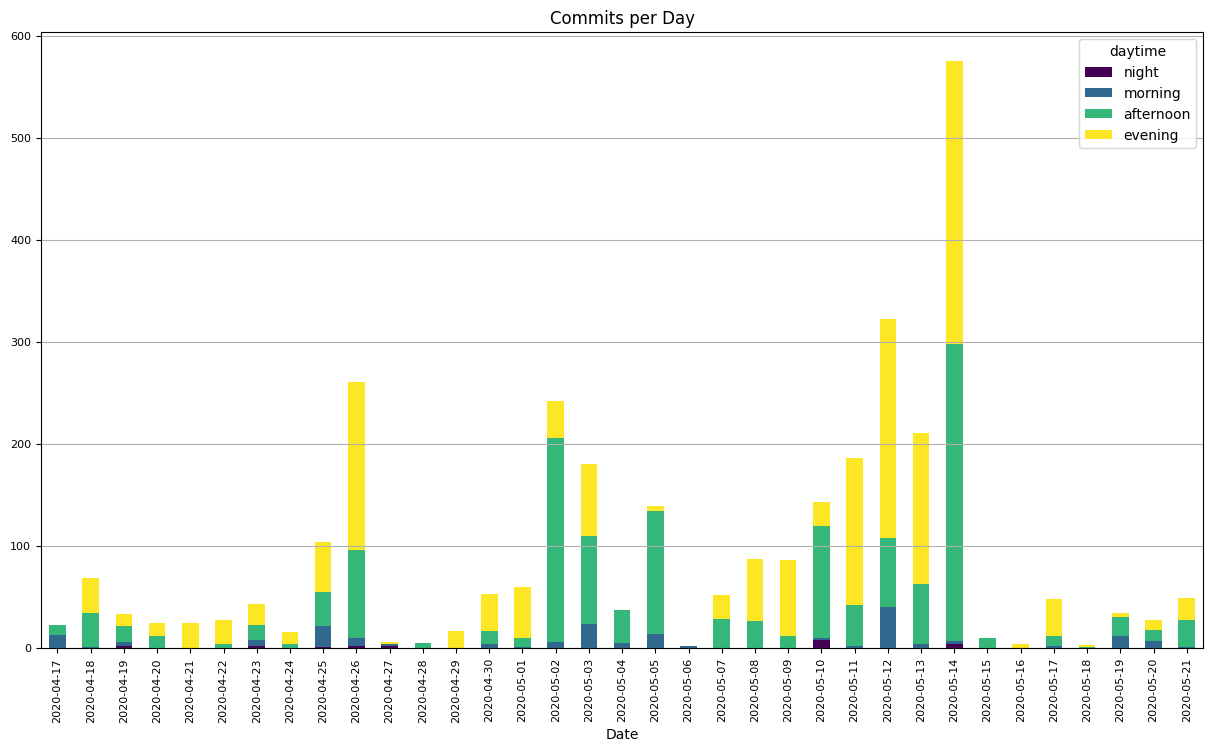

In [15]:
ax = daily_periods.plot(
    kind='bar',
    stacked=True,
    figsize=(15,8),
    fontsize=8,
    rot=90,
    colormap='viridis',
    title='Commits per Day'
)
ax.set_xlabel('Date')
ax.grid(True, axis='y')
conn.close()

### When do our users usually commit to the labs: in the night, morning, afternoon, or evening?

Answer: afternoon, evening

### Which day has:

### the most number of commits?

Answer: 2020-05-12

### and at the same time, is the number of commits higher in the evening than in the afternoon?

In [16]:
evening_vs_afternoon = daily_periods.loc[daily_periods['evening'] > daily_periods['afternoon']].copy()
evening_vs_afternoon['total'] = evening_vs_afternoon.sum(axis=1)

special_day = evening_vs_afternoon['total'].idxmax()
print(f"Answer: {special_day}")

Answer: 2020-05-12
